Path found:
[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7)]
Path length: 14 steps
Cells explored: 53


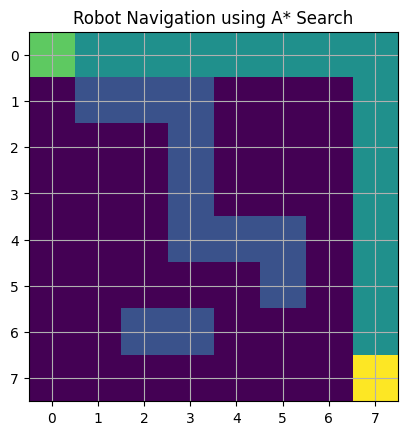

In [3]:

import heapq
import matplotlib.pyplot as plt
import numpy as np

# Create an 8 x 8 grid
grid = np.zeros((8, 8))

# Define start, goal and obstacles
start = (0, 0)
goal = (7, 7)

obstacles = [
    (1, 1), (1, 2), (1, 3),
    (2, 3), (3, 3), (4, 3),
    (4, 4), (4, 5), (5, 5),
    (6, 2), (6, 3)
]

for obstacle in obstacles:
    grid[obstacle] = 1

# Manhattan distance heuristic
def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

# A* Search algorithm
def astar(start, goal):
    pq = [(heuristic(start, goal), 0, start, [start])]
    visited = set()
    explored = 0

    while pq:
        f, g, current, path = heapq.heappop(pq)

        if current in visited:
            continue

        visited.add(current)
        explored += 1

        if current == goal:
            return path, explored

        row, col = current

        # Up, down, left, right
        directions = [
            (-1, 0), (1, 0),
            (0, -1), (0, 1)
        ]

        for dr, dc in directions:
            nr, nc = row + dr, col + dc
            neighbor = (nr, nc)

            if (0 <= nr < 8 and 0 <= nc < 8
                and grid[nr, nc] == 0
                and neighbor not in visited):

                new_g = g + 1
                new_f = new_g + heuristic(neighbor, goal)

                heapq.heappush(
                    pq, (new_f, new_g, neighbor,
                         path + [neighbor])
                )

    return None, explored


# Run A*
path, explored = astar(start, goal)

if path:
    print("Path found:")
    print(path)
    print("Path length:", len(path) - 1, "steps")
    print("Cells explored:", explored)

    # Display grid
    display_grid = grid.copy()

    for r, c in path:
        display_grid[r, c] = 2

    display_grid[start] = 3
    display_grid[goal] = 4

    plt.imshow(display_grid, cmap="viridis")

    plt.xticks(range(8))
    plt.yticks(range(8))
    plt.grid(True)
    plt.title("Robot Navigation using A* Search")
    plt.show()

else:
    print("No valid path found.")
    print("Cells explored:", explored)
